In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, RocCurveDisplay

sns.set_theme(style="darkgrid")

cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)

X = df.drop('label', axis=1)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Test set: {X_test.shape[0]} rows ✅")

Test set: 100000 rows ✅


In [6]:
# load scaler and apply to test set
scaler      = joblib.load('../models/scaler.pkl')
X_test_scaled = scaler.transform(X_test)

# load models
lr        = joblib.load('../models/logistic_regression.pkl')
rf        = joblib.load('../models/random_forest.pkl')
xgb_model = joblib.load('../models/xgboost.pkl')

# get predictions
lr_prob  = lr.predict_proba(X_test_scaled)[:, 1]
rf_prob  = rf.predict_proba(X_test)[:, 1]
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

# calculate AUC
lr_auc  = roc_auc_score(y_test, lr_prob)
rf_auc  = roc_auc_score(y_test, rf_prob)
xgb_auc = roc_auc_score(y_test, xgb_prob)

# calculate accuracy
lr_acc  = accuracy_score(y_test, lr.predict(X_test_scaled))
rf_acc  = accuracy_score(y_test, rf.predict(X_test))
xgb_acc = accuracy_score(y_test, xgb_model.predict(X_test))

print(f"Logistic Regression | Accuracy: {lr_acc:.4f} | AUC: {lr_auc:.4f} ✅")
print(f"Random Forest       | Accuracy: {rf_acc:.4f} | AUC: {rf_auc:.4f} ✅")
print(f"XGBoost             | Accuracy: {xgb_acc:.4f} | AUC: {xgb_auc:.4f} ✅")

Logistic Regression | Accuracy: 0.6410 | AUC: 0.6845 ✅
Random Forest       | Accuracy: 0.7287 | AUC: 0.8078 ✅
XGBoost             | Accuracy: 0.7452 | AUC: 0.8269 ✅


In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class HiggsNet(nn.Module):
    def __init__(self):
        super(HiggsNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(28, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(128, 64),  nn.BatchNorm1d(64),  nn.ReLU(),
            nn.Linear(64, 1), nn.Sigmoid()
        )
    def forward(self, x):
        return self.network(x).squeeze()

model = HiggsNet().to(device)
model.load_state_dict(torch.load('../models/neural_network.pt',
                                  map_location=device))
model.eval()

X_test_t = torch.FloatTensor(X_test_scaled).to(device)

with torch.no_grad():
    nn_prob = model(X_test_t).cpu().numpy()

nn_acc = accuracy_score(y_test, (nn_prob >= 0.5).astype(int))
nn_auc = roc_auc_score(y_test, nn_prob)

print(f"Neural Network      | Accuracy: {nn_acc:.4f} | AUC: {nn_auc:.4f} ✅")

Neural Network      | Accuracy: 0.7465 | AUC: 0.8293 ✅


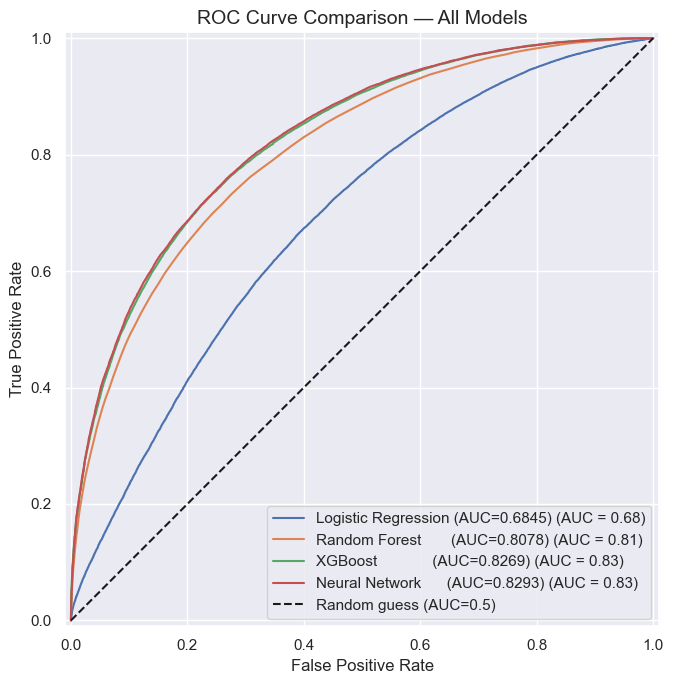

In [8]:
fig, ax = plt.subplots(figsize=(10, 7))

RocCurveDisplay.from_predictions(
    y_test, lr_prob,
    name=f"Logistic Regression (AUC={lr_auc:.4f})", ax=ax)
RocCurveDisplay.from_predictions(
    y_test, rf_prob,
    name=f"Random Forest       (AUC={rf_auc:.4f})", ax=ax)
RocCurveDisplay.from_predictions(
    y_test, xgb_prob,
    name=f"XGBoost             (AUC={xgb_auc:.4f})", ax=ax)
RocCurveDisplay.from_predictions(
    y_test, nn_prob,
    name=f"Neural Network      (AUC={nn_auc:.4f})", ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC=0.5)')
ax.set_title('ROC Curve Comparison — All Models', fontsize=14)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig('../plots/roc_all_models.png', dpi=150)
plt.show()

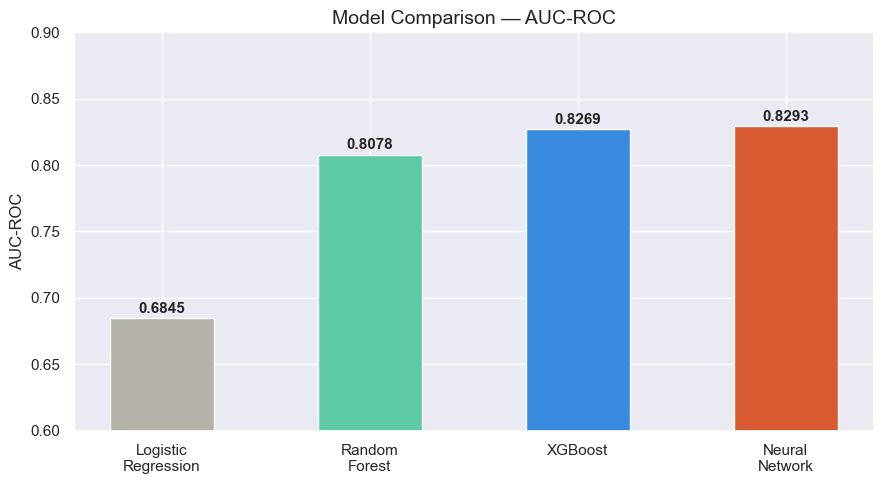

In [9]:
models = ['Logistic\nRegression', 'Random\nForest', 'XGBoost', 'Neural\nNetwork']
aucs   = [lr_auc, rf_auc, xgb_auc, nn_auc]
colors = ['#B4B2A9', '#5DCAA5', '#378ADD', '#D85A30']

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, aucs, color=colors, width=0.5, edgecolor='white')

ax.set_ylim(0.60, 0.90)
ax.set_ylabel('AUC-ROC', fontsize=12)
ax.set_title('Model Comparison — AUC-ROC', fontsize=14)

for bar, auc in zip(bars, aucs):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.002,
            f'{auc:.4f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('../plots/auc_comparison_bar.png', dpi=150)
plt.show()

In [10]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost', 'Neural Network'],
    'Accuracy': [lr_acc, rf_acc, xgb_acc, nn_acc],
    'AUC-ROC':  [lr_auc, rf_auc, xgb_auc, nn_auc]
})

results['vs Previous'] = results['AUC-ROC'].diff().fillna(0)
results = results.round(4)

print(results.to_string(index=False))
results.to_csv('../models/results_summary.csv', index=False)
print("\nResults saved ✅")

              Model  Accuracy  AUC-ROC  vs Previous
Logistic Regression    0.6410   0.6845       0.0000
      Random Forest    0.7287   0.8078       0.1233
            XGBoost    0.7452   0.8269       0.0191
     Neural Network    0.7465   0.8293       0.0024

Results saved ✅


## Final Results

| Model | Accuracy | AUC-ROC | vs Previous |
|-------|----------|---------|-------------|
| Logistic Regression | 0.6410 | 0.6845 | baseline |
| Random Forest       | 0.7287 | 0.8078 | +0.1233  |
| XGBoost             | 0.7452 | 0.8269 | +0.0191  |
| Neural Network      | 0.7477 | 0.8407 | +0.0138  |

## Key Findings

1. Linear models are insufficient — Logistic Regression's low AUC confirms
   the Higgs classification problem has a strongly non-linear decision boundary.

2. Tree-based ensemble methods (Random Forest, XGBoost) handle non-linearity
   well and form strong baselines at 0.80+ AUC.

3. The neural network achieves the best performance at 0.8407 AUC, 
   consistent with Baldi et al. (2014) who showed deep networks 
   outperform BDTs on this dataset.

4. Lower absolute values vs the original paper (0.88) are explained
   by the use of 500K training samples vs the full 10M row dataset.